# DSA 107 — Lab 1: Environment and first notebook

**Week 1 · w/c 28 September 2026** · paired with DSA 101 lecture week 1

**Name:** Hatice Beyza Çaylı   **Student ID:** 26022121461

---

### What you will produce

A runnable Colab notebook, pushed to your own GitHub repository, that loads a dataset, answers four questions about it, and draws one labelled figure.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install pandas matplotlib seaborn scikit-learn` in a new cell and try again.


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


## 1. Load the data

`pd.read_csv` accepts a URL as happily as a filename. Load the penguins dataset into a DataFrame called `penguins`.

In [30]:
penguins = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv")

# TODO: show the first five rows
# penguins.head(10)

penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 2. How big is it, and what is in it?

Three commands answer almost every first question about a dataset:

- `.shape` — rows and columns
- `.info()` — column names, types, and how many non-missing values each has
- `.describe()` — summary statistics for the numeric columns

In [31]:
# TODO: print the shape, then call .info()


penguins.shape
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [32]:
# TODO: summary statistics for the numeric columns

penguins.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


### Missing values

`.isna()` gives a True/False table the same shape as the data. Summing it down the columns counts the missing values in each.

In [33]:
# TODO: count the missing values in each column

penguins.isna()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,True,True,True,True,True
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
339,False,False,True,True,True,True,True
340,False,False,False,False,False,False,False
341,False,False,False,False,False,False,False
342,False,False,False,False,False,False,False


**Q1.** How many penguins are in the dataset, and how many columns describe each one?

- The dataset contains 344 penguins, and each is described by 7 columns.

----

**Q2.** Which column has the most missing values, and how many? Suggest one plausible reason a field measurement might be missing.

-    The highest number of missing value is found in the *sex* column; there are 11 missing values. Problems may have occured with the penguins or the measuring equipment during the measurement.

## 3. Selecting and filtering

A single column is `df["name"]`. Several columns is `df[["a", "b"]]` — note the double brackets. Rows are chosen with a condition: `df[df["col"] > 5]`.

In [34]:
# TODO: show only species, island and body_mass_g, first five rows

penguins[["species", "island", "body_mass_g"]].head()


,species,island,body_mass_g
0,Adelie,Torgersen,3750.0
1,Adelie,Torgersen,3800.0
2,Adelie,Torgersen,3250.0
3,Adelie,Torgersen,NaN
4,Adelie,Torgersen,3450.0


In [35]:
# TODO: make a DataFrame called gentoo holding only the Gentoo penguins,
# then print how many there are

gentoo = penguins[penguins["species"] == "Gentoo"]
print(len(gentoo))


124


**Q3.** How many Gentoo penguins are there? What fraction of the dataset is that?

In [36]:
# TODO: compute and print the fraction


print(len(gentoo))
fraction=len(gentoo) / len(penguins)
print(fraction)

124
0.36046511627906974


## 4. Your first figure

A scatter plot of two numeric columns, coloured by a third categorical one. Every figure in this course needs axis labels and a title — a plot without them is not a finished piece of work.

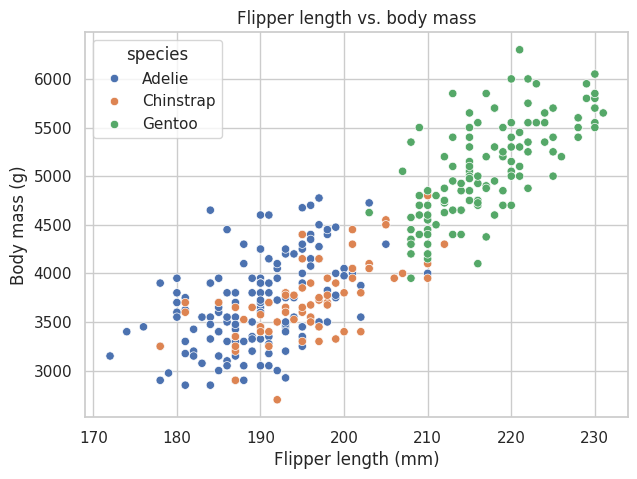

In [37]:
fig, ax = plt.subplots(figsize=(7, 5))
# TODO: scatter plot of flipper_length_mm against body_mass_g,
#       coloured by species, with labels and a title

sns.scatterplot(data=penguins,
                x="flipper_length_mm",
                y="body_mass_g",
                hue="species",
                ax=ax)

ax.set_title("Flipper length vs. body mass")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")

plt.show()

**Q4.** Describe the relationship in two sentences. Does it hold within every species, or only across all three together? What would you check next?

- There is a positive relationship between body mass and flipper length. As penguins get heavier, their flippers get longer. This pattern holds true within every species, not just across all three together. Next, I would check the data to see if male and female penguins show different patterns.

## 5. Push to GitHub

1. Create a repository named `dsa107-labs` on GitHub (public is fine).
2. In Colab: **File → Save a copy in GitHub**, choose that repository.
3. Paste the resulting link in the cell below.

**Repository link:** https://github.com/haticecayli/dsa107-labs.git

---

## Submission checklist

- [ ] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [ ] Every written answer is filled in — a plot with no reading of it scores zero on interpretation
- [ ] Notebook saved as `Lab01_Firstname_Lastname.ipynb`
- [ ] Report exported as `Lab01_Firstname_Lastname.pdf`
- [ ] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.